Dataset Loaded Successfully!

First 5 Rows:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage

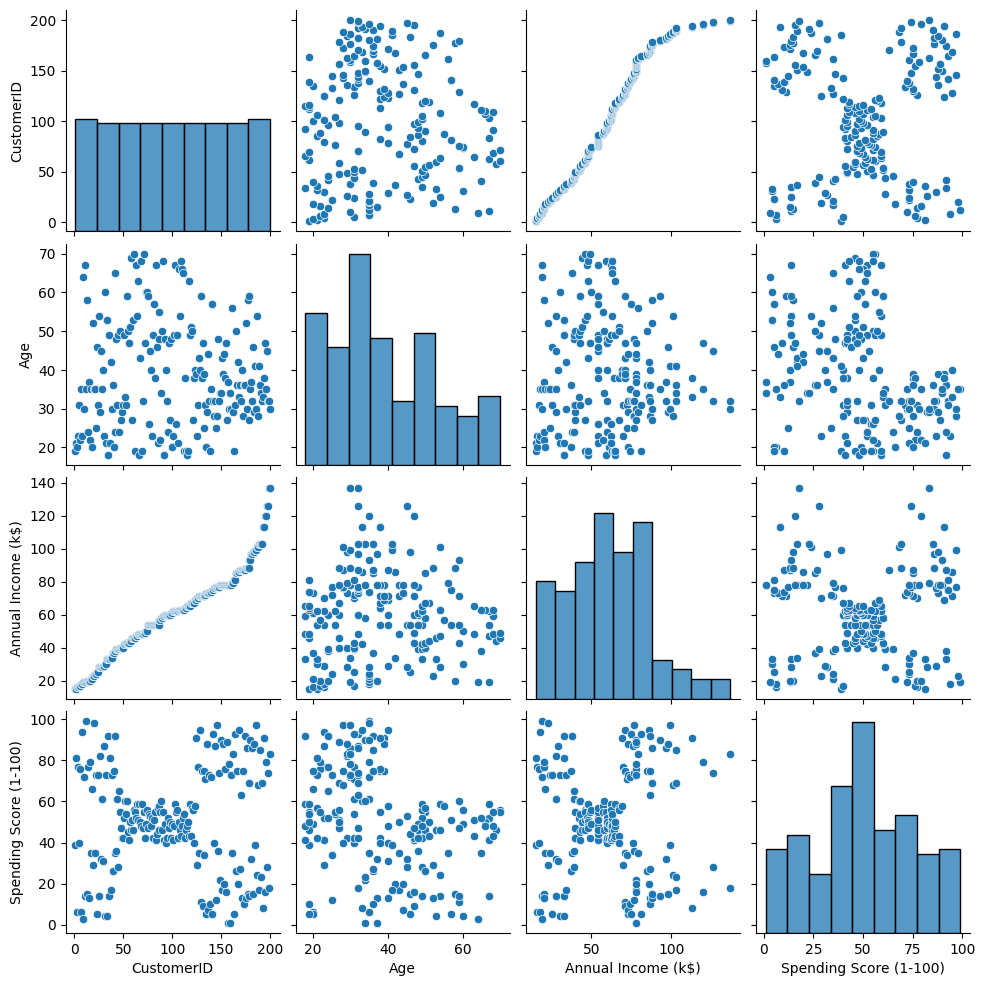


K-Means Model Trained Successfully!

Clustered Data:
   Annual Income (k$)  Spending Score (1-100)  label
0                  15                      39      4
1                  15                      81      2
2                  16                       6      4
3                  16                      77      2
4                  17                      40      4


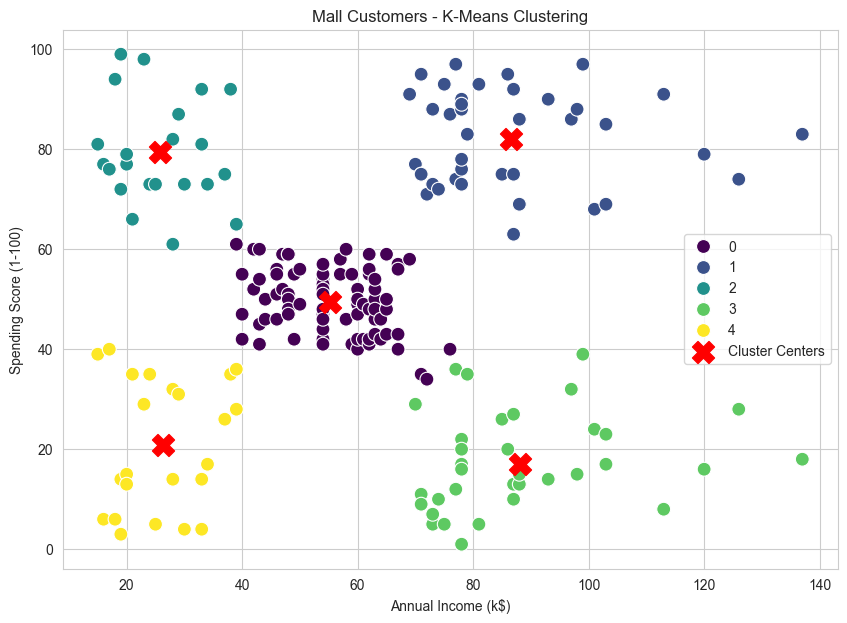

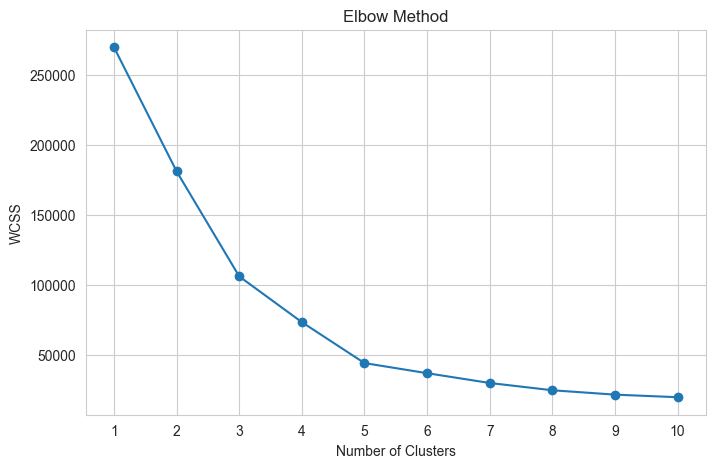


Cluster Centers:
[[55.2962963  49.51851852]
 [86.53846154 82.12820513]
 [25.72727273 79.36363636]
 [88.2        17.11428571]
 [26.30434783 20.91304348]]

Customers in Each Cluster:
label
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

Mall Customer Segmentation Completed Successfully!


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tkinter import Tk, filedialog
from sklearn.cluster import KMeans
root = Tk()
root.withdraw()
root.attributes("-topmost", True)
file_path = filedialog.askopenfilename(
    title="Select Mall_Customers.csv",
    filetypes=[("CSV Files", "*.csv")]
)
root.destroy()
if not file_path:
    raise ValueError("Please select the Mall_Customers.csv file.")
df = pd.read_csv(file_path)
print("Dataset Loaded Successfully!")
print("\nFirst 5 Rows:")
print(df.head())
print("\nDataset Information:")
df.info()
sns.pairplot(df)
plt.show()
features = df[["Annual Income (k$)", "Spending Score (1-100)"]].values
model = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)
model.fit(features)
print("\nK-Means Model Trained Successfully!")
Final = df[["Annual Income (k$)", "Spending Score (1-100)"]].copy()
Final["label"] = model.labels_
print("\nClustered Data:")
print(Final.head())
sns.set_style("whitegrid")
plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=Final,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="label",
    palette="viridis",
    s=100
)
plt.scatter(
    model.cluster_centers_[:, 0],
    model.cluster_centers_[:, 1],
    s=250,
    marker="X",
    color="red",
    label="Cluster Centers"
)
plt.title("Mall Customers - K-Means Clustering")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.show()
wcss = []
for i in range(1, 11):
    km = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    km.fit(features)
    wcss.append(km.inertia_)


# STEP 9: Plot the Elbow Graph

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker="o"
)

plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()


# STEP 10: Display Cluster Centers

print("\nCluster Centers:")
print(model.cluster_centers_)


# STEP 11: Display Number of Customers in Each Cluster

print("\nCustomers in Each Cluster:")
print(Final["label"].value_counts().sort_index())


# STEP 12: Project Completed

print("\nMall Customer Segmentation Completed Successfully!")